# Task 2 (Instance Segmentation) — Rank 1 Commercial Model Test: `RF-DETR-Seg-M`

**Objective:** Verify `RF-DETR-Seg` (`RFDETRSegMedium`, **Apache-2.0** across all sizes `N`–`2XL`) end-to-end against `f:\IRIS\surveillance-new`'s Barber & Proximity pipelines:
1. Store **all** downloaded weights, caches, venv, and exported ONNX files strictly inside **`notebooks/downloads/`**.
2. Run PyTorch `RFDETRSegMedium` instance segmentation (`m.predict()`) on real local IRIS surveillance frames (`calib_images/*.jpg`).
3. Audit **actual** IRIS codebase integration contracts:
   - [nvdsparseseg_Yolo.cpp](file:///f:/IRIS/surveillance-new/perception/models/DeepStream-Yolo-Seg/nvdsinfer_custom_impl_Yolo_seg/nvdsparseseg_Yolo.cpp) single-tensor `[N, 6 + (netW/4)*(netH/4)]` layout
   - [person_masks/outline.py](file:///f:/IRIS/surveillance-new/perception/modules/person_masks/outline.py) & [proximity/shapes.py](file:///f:/IRIS/surveillance-new/perception/modules/proximity/shapes.py) **box-relative** mask expectation (`ROI` grid inside `o.bbox`, NOT full-frame!)
   - Rectangular resolution constraint (`block_size = patch_size * num_windows = 24`) vs Barber (`384×640` → `384×648`) and Proximity (`736×1280` → `744×1296` / `720×1272`)
   - COCO-91 → COCO-80 (`0 = person`) remapping & ImageNet normalization baking
4. Export BOTH **`432×432`** (native square) and **`384×648`** (Barber-aligned rectangular, `batch=3`) DeepStream ONNX models with **in-graph `F.grid_sample` box-cropped masks** (zero custom TensorRT `EfficientNMSX_TRT`/`ROIAlignX_TRT` plugins needed!), validate ORT CUDA inference, verify mask IoU vs PyTorch, and feed real outputs directly through IRIS's `outline()` and `blob_of()`/`person_shape()`.


In [1]:
import importlib.metadata
import os
import re
import sys
import time
from copy import deepcopy
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "perception" / "engine" / "engine_path.py").is_file():
            return p
    raise FileNotFoundError("Could not locate IRIS repository root from " + str(start))

REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Route ALL model downloads & caches into notebooks/downloads/
DOWNLOADS_DIR = REPO_ROOT / "notebooks" / "downloads"
MODELS_CACHE_DIR = DOWNLOADS_DIR / "models_cache"
ONNX_EXPORT_DIR = DOWNLOADS_DIR / "onnx_exports"
MODELS_CACHE_DIR.mkdir(parents=True, exist_ok=True)
ONNX_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["RF_HOME"] = str(MODELS_CACHE_DIR)
os.environ["ROBOFLOW_HOME"] = str(MODELS_CACHE_DIR)
os.environ["HF_HOME"] = str(MODELS_CACHE_DIR / "hf")
os.environ["TORCH_HOME"] = str(MODELS_CACHE_DIR / "torch")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from rfdetr import RFDETRSegMedium
from rfdetr.assets.coco_classes import COCO_CLASSES
from rfdetr.export._runtime.preprocess import IMAGENET_MEAN, IMAGENET_STD

from perception.engine.engine_path import _parse as parse_engine_cfg, assert_distinct_engine_paths
from perception.engine.model_manifest import NVINFER_FILE_KEYS
from perception.engine.nvds import InstanceMask
from perception.modules.person_masks.outline import outline
from perception.modules.proximity.shapes import blob_of, outline_polygon, person_shape

CALIB_DIR = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images"
SEG_LABELS_PATH = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Seg" / "labels.txt"

calib_images = sorted(CALIB_DIR.glob("*.jpg"))
seg_labels = [l.strip() for l in SEG_LABELS_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]

print(f"Repo root          : {REPO_ROOT}")
print(f"Downloads hub      : {DOWNLOADS_DIR.relative_to(REPO_ROOT)} (RF_HOME={os.environ['RF_HOME']})")
print(f"PyTorch            : {torch.__version__} | CUDA: {torch.cuda.is_available()}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print(f"rfdetr             : {importlib.metadata.version('rfdetr')} (Apache-2.0)")
print(f"ONNX / ORT         : {onnx.__version__} / {ort.__version__}")
print(f"ORT providers      : {ort.get_available_providers()}")
print(f"Local calib frames : {len(calib_images)} JPEGs | Seg labels: {len(seg_labels)} (0={seg_labels[0]!r}, 2={seg_labels[2]!r})")
assert len(seg_labels) == 80 and seg_labels[0] == "person"


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Repo root          : F:\IRIS\surveillance-new
Downloads hub      : notebooks\downloads (RF_HOME=F:\IRIS\surveillance-new\notebooks\downloads\models_cache)
PyTorch            : 2.14.1+cu130 | CUDA: True (Quadro RTX 3000)
rfdetr             : 1.12.1 (Apache-2.0)
ONNX / ORT         : 1.23.2 / 1.32.0
ORT providers      : ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Local calib frames : 60 JPEGs | Seg labels: 80 (0='person', 2='car')


## 1. Native PyTorch `RFDETRSegMedium` Instance Segmentation Inference

Run `RFDETRSegMedium` (Apache-2.0, downloaded strictly to `notebooks/downloads/models_cache/`) on 4 representative surveillance frames (`frame_00014.jpg`, `frame_00041.jpg`, `frame_00051.jpg`, `frame_00055.jpg`) and render masks + boxes.


[2026-11-16 14:08:09] [INFO] rf-detr - File F:\IRIS\surveillance-new\notebooks\downloads\models_cache\rf-detr-seg-medium.pt already exists with correct MD5 hash.


[2026-11-16 14:08:10] [INFO] rf-detr - File F:\IRIS\surveillance-new\notebooks\downloads\models_cache\rf-detr-seg-medium.pt already exists with correct MD5 hash.


RFDETRSegMedium: native_res=432x432, patch_size=12, num_windows=2, block_size=24, num_classes=90


[2026-11-16 14:08:11] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


  frame_00014.jpg | size=(1080, 720) | dets= 5 | mask=(5, 720, 1080) |  102.6 ms | classes=['person', 'person', 'person', 'person', 'person']
  frame_00041.jpg | size=(1080, 720) | dets= 2 | mask=(2, 720, 1080) |  102.6 ms | classes=['person', 'person']
  frame_00051.jpg | size=(1080, 720) | dets= 8 | mask=(8, 720, 1080) |   73.2 ms | classes=['person', 'person', 'person', 'umbrella', 'person', 'person', 'person', 'person']


  frame_00055.jpg | size=(1080, 720) | dets= 6 | mask=(6, 720, 1080) |   72.7 ms | classes=['person', 'person', 'person', 'umbrella', 'person', 'umbrella']


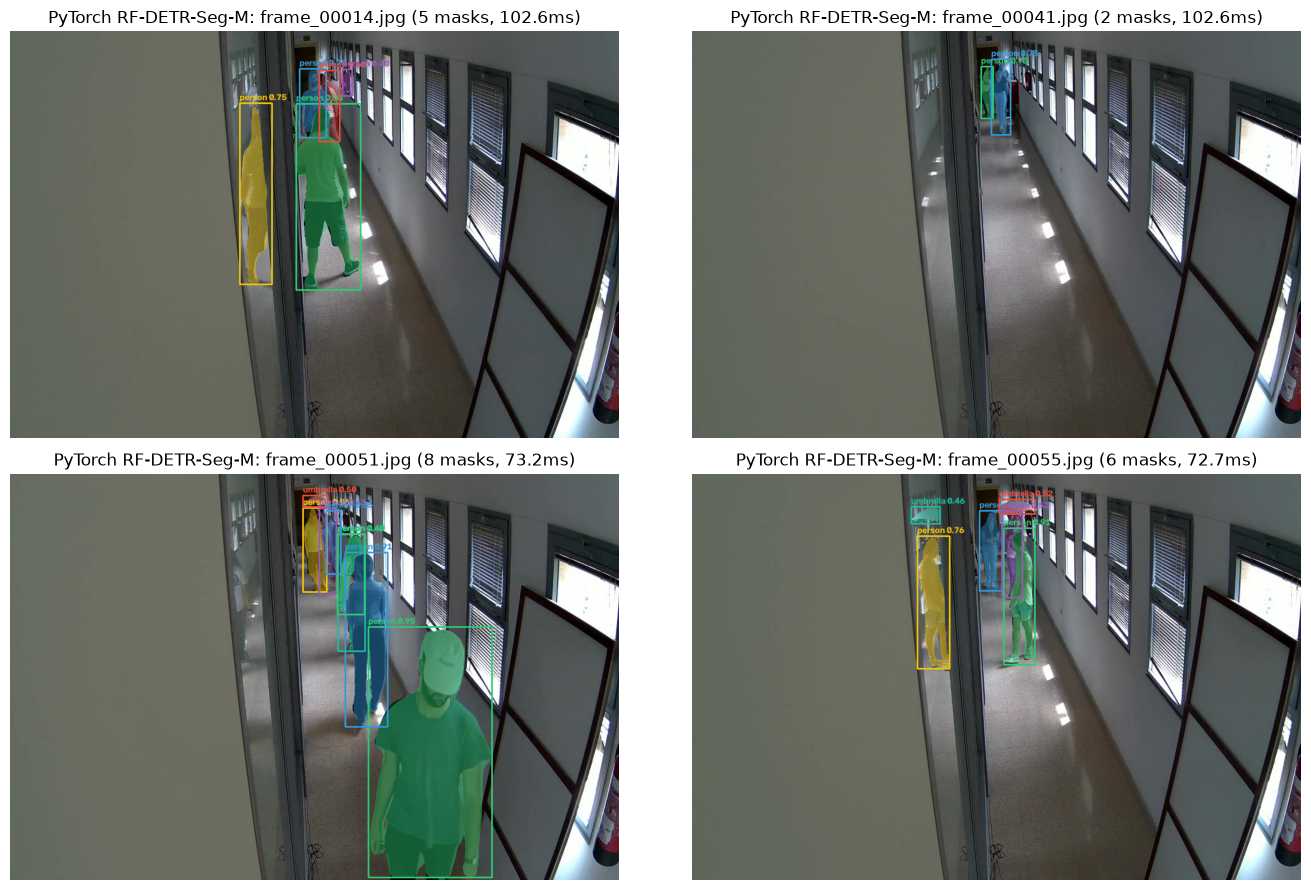

In [2]:
SAMPLE_NAMES = ["frame_00014.jpg", "frame_00041.jpg", "frame_00051.jpg", "frame_00055.jpg"]
SAMPLE_PATHS = [CALIB_DIR / n for n in SAMPLE_NAMES]
CONF_THRESH = 0.35

pt_seg = RFDETRSegMedium()
mc = pt_seg.model_config
NATIVE_RES = int(mc.resolution)
BLOCK_SIZE = int(mc.patch_size) * int(getattr(mc, "num_windows", 1))
print(f"RFDETRSegMedium: native_res={NATIVE_RES}x{NATIVE_RES}, patch_size={mc.patch_size}, "
      f"num_windows={getattr(mc, 'num_windows', 1)}, block_size={BLOCK_SIZE}, num_classes={mc.num_classes}")

_ = pt_seg.predict(Image.open(SAMPLE_PATHS[0]).convert("RGB"), threshold=CONF_THRESH)
if torch.cuda.is_available():
    torch.cuda.synchronize()

pt_results = {}
for p in SAMPLE_PATHS:
    im = Image.open(p).convert("RGB")
    t0 = time.perf_counter()
    det = pt_seg.predict(im, threshold=CONF_THRESH)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) * 1000.0
    names = [COCO_CLASSES[int(c)] for c in det.class_id]
    pt_results[p.name] = (im, det, names, ms)
    mshape = None if det.mask is None else det.mask.shape
    print(f"  {p.name:15s} | size={im.size} | dets={len(det):2d} | mask={mshape} | {ms:6.1f} ms | classes={names}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rng = np.random.default_rng(42)
palette = [(46, 204, 113), (52, 152, 219), (241, 196, 15), (231, 76, 60), (155, 89, 182), (26, 188, 156)]
for ax, name in zip(axes.flat, SAMPLE_NAMES):
    im, det, cls_names, ms = pt_results[name]
    overlay = np.array(im, dtype=np.float32)
    if det.mask is not None:
        for i, m_bool in enumerate(det.mask):
            col = np.array(palette[i % len(palette)], dtype=np.float32)
            overlay[m_bool] = overlay[m_bool] * 0.55 + col * 0.45
    canvas = overlay.clip(0, 255).astype(np.uint8)
    for i, ((x1, y1, x2, y2), conf, cname) in enumerate(zip(det.xyxy, det.confidence, cls_names)):
        col = palette[i % len(palette)]
        cv2.rectangle(canvas, (int(x1), int(y1)), (int(x2), int(y2)), col, 2)
        cv2.putText(canvas, f"{cname} {conf:.2f}", (int(x1), max(18, int(y1) - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)
    ax.imshow(canvas)
    ax.set_title(f"PyTorch RF-DETR-Seg-M: {name} ({len(det)} masks, {ms:.1f}ms)")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. IRIS Codebase Audit (Seg C++ Parser, Downstream Mask Geometry & Rectangular Constraints)

Let's programmatically check the exact contracts across:
1. [nvdsparseseg_Yolo.cpp](file:///f:/IRIS/surveillance-new/perception/models/DeepStream-Yolo-Seg/nvdsinfer_custom_impl_Yolo_seg/nvdsparseseg_Yolo.cpp): expects **one** tensor `[N, 6 + (netW/4)*(netH/4)]`, reading `[bx1, by1, bx2, by2, conf, class_id]` + `(netH/4) × (netW/4)` mask floats.
2. [outline.py](file:///f:/IRIS/surveillance-new/perception/modules/person_masks/outline.py) & [shapes.py](file:///f:/IRIS/surveillance-new/perception/modules/proximity/shapes.py): map that `(netH/4, netW/4)` grid **relative to the object's bounding box `o.bbox`**, NOT over the whole frame! Raw `RF-DETR-Seg` emits **full-frame** mask maps `[B, 200, Hm, Wm]`. Without per-box ROI sampling, outlines and foot locations would be completely wrong.
3. **Rectangular resolution check (`block_size = 24`)**: Compare IRIS's current `YOLO26l-seg` configs (`384×640` Barber, `736×1280` Proximity) against nearest valid multiples of `24` (`384×648` for Barber, `744×1296` or `720×1272` for Proximity).


In [3]:
seg_cpp = (REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Seg" /
           "nvdsinfer_custom_impl_Yolo_seg" / "nvdsparseseg_Yolo.cpp").read_text(encoding="utf-8")
barber_cfg_p = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Seg" / "config_infer_primary_yolo26l_seg_r384.txt"
prox_cfg_p = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Seg" / "config_infer_primary_yolo26l_seg_1280.txt"
outline_src = (REPO_ROOT / "perception" / "modules" / "person_masks" / "outline.py").read_text(encoding="utf-8")
shapes_src = (REPO_ROOT / "perception" / "modules" / "proximity" / "shapes.py").read_text(encoding="utf-8")

assert "b.mask_width = netW / 4;" in seg_cpp and "b.mask_height = netH / 4;" in seg_cpp
assert "channelsSize - 6" in seg_cpp
assert "left + (pts[:, 0] + 0.5) * w / mw" in outline_src
assert "self.left + (np.asarray(cols, float) + 0.5) * self.cell_w" in shapes_src

def nearest_valid_hw(h: int, w: int, block: int) -> tuple[int, int]:
    nh = int(round(h / block)) * block
    nw = int(round(w / block)) * block
    return nh, nw

barber_hw = (384, 640)
prox_hw = (736, 1280)
print(f"nvdsparseseg_Yolo.cpp contract   : [N, 6 + (netW/4)*(netH/4)] Verified")
print(f"Downstream outline.py / shapes.py: Both expect BOX-RELATIVE mask grid over o.bbox (Verified)")
print(f"Barber 384x640 % block({BLOCK_SIZE})       : {(barber_hw[0]%BLOCK_SIZE, barber_hw[1]%BLOCK_SIZE)} -> nearest valid: {nearest_valid_hw(*barber_hw, BLOCK_SIZE)}")
print(f"Proximity 736x1280 % block({BLOCK_SIZE})   : {(prox_hw[0]%BLOCK_SIZE, prox_hw[1]%BLOCK_SIZE)} -> nearest valid: {nearest_valid_hw(*prox_hw, BLOCK_SIZE)} (alt floor/ceil: (720, 1272) or (744, 1296))")


nvdsparseseg_Yolo.cpp contract   : [N, 6 + (netW/4)*(netH/4)] Verified
Downstream outline.py / shapes.py: Both expect BOX-RELATIVE mask grid over o.bbox (Verified)
Barber 384x640 % block(24)       : (0, 16) -> nearest valid: (384, 648)
Proximity 736x1280 % block(24)   : (16, 8) -> nearest valid: (744, 1272) (alt floor/ceil: (720, 1272) or (744, 1296))


## 3. DeepStream Drop-In ONNX Export (`DeepStreamRFDETRSeg` with In-Graph `GridSample` ROI Crop)

We build a single `nn.Module` wrapper (`DeepStreamRFDETRSeg`) that:
1. Bakes ImageNet normalization `(x - mean) / std` inside ONNX (so IRIS `nvinfer` `net-scale-factor=0.0039215697906911373` works exact).
2. Runs export-mode `LWDETR` (`boxes_cxcywh`, `logits_91`, `masks_fullframe [B, 200, netH/4, netW/4]`).
3. Remaps COCO-91 → COCO-80 (`0 = person`) so `labels.txt` and `operate-on-class-ids=0` SGIEs stay unchanged.
4. **Crops/pools each query's full-frame mask onto its own predicted `[bx1, by1, bx2, by2]` box via standard ONNX `F.grid_sample(..., align_corners=False)`** at target resolution `(netH//4, netW//4)` and applies `.sigmoid()`, emitting **one single tensor `[B, 200, 6 + (netH//4)*(netW//4)]`** — matching `nvdsparseseg_Yolo.cpp` and `outline.py` / `shapes.py` with **zero custom TensorRT plugins**!

We export & validate **two** configurations:
- **`432×432`** (native RFDETRSegMedium resolution, `mask_grid = 108×108`, output `[B, 200, 11670]`)
- **`384×648`** (Barber rectangular alignment closest to `384×640`, `mask_grid = 96×162`, output `[B, 200, 15558]`)


In [4]:
COCO91_TO_80_INDICES = sorted(COCO_CLASSES.keys())

class DeepStreamRFDETRSeg(nn.Module):
    def __init__(self, core_model: nn.Module, img_h: int, img_w: int, bake_imagenet_norm: bool = True):
        super().__init__()
        self.core = core_model
        self.img_h = int(img_h)
        self.img_w = int(img_w)
        self.mask_h = self.img_h // 4
        self.mask_w = self.img_w // 4
        self.bake_imagenet_norm = bake_imagenet_norm
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("coco_idx", torch.tensor(COCO91_TO_80_INDICES, dtype=torch.long))
        self.register_buffer(
            "convert_matrix",
            torch.tensor([[1, 0, 1, 0], [0, 1, 0, 1], [-0.5, 0, 0.5, 0], [0, -0.5, 0, 0.5]], dtype=torch.float32),
        )
        self.register_buffer("scale_xyxy", torch.tensor([[[self.img_w, self.img_h, self.img_w, self.img_h]]], dtype=torch.float32))
        cx = ((torch.arange(self.mask_w, dtype=torch.float32) + 0.5) / self.mask_w).view(1, 1, 1, self.mask_w)
        cy = ((torch.arange(self.mask_h, dtype=torch.float32) + 0.5) / self.mask_h).view(1, 1, self.mask_h, 1)
        self.register_buffer("grid_cx", cx)
        self.register_buffer("grid_cy", cy)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.bake_imagenet_norm:
            x = (x - self.mean) / self.std
        boxes_cxcywh, logits, masks = self.core(x)[:3]
        b_sz, q_sz, h_m, w_m = masks.shape
        boxes_norm = (boxes_cxcywh @ self.convert_matrix).clamp(0.0, 1.0)
        boxes_xyxy = boxes_norm * self.scale_xyxy

        # Exact inverse of perception/modules/person_masks/outline.py box->frame mapping
        x1, y1, x2, y2 = [boxes_norm[..., i:i+1].unsqueeze(-1) for i in range(4)]
        ux = 2.0 * (x1 + (x2 - x1).clamp(min=1e-6) * self.grid_cx) - 1.0
        uy = 2.0 * (y1 + (y2 - y1).clamp(min=1e-6) * self.grid_cy) - 1.0
        grid = torch.stack([ux.expand(-1, -1, self.mask_h, -1), uy.expand(-1, -1, -1, self.mask_w)], dim=-1)
        pooled = F.grid_sample(
            masks.reshape(b_sz * q_sz, 1, h_m, w_m),
            grid.reshape(b_sz * q_sz, self.mask_h, self.mask_w, 2),
            mode="bilinear",
            padding_mode="zeros",
            align_corners=False,
        )
        mask_flat = pooled.sigmoid().reshape(b_sz, q_sz, self.mask_h * self.mask_w)

        logits_80 = logits.index_select(-1, self.coco_idx)
        scores, labels = torch.max(logits_80.sigmoid(), dim=-1, keepdim=True)
        return torch.cat([boxes_xyxy, scores, labels.to(boxes_xyxy.dtype), mask_flat], dim=-1)

def export_ds_seg_onnx(base_model: RFDETRSegMedium, h: int, w: int, filename: str) -> Path:
    from rfdetr.models.backbone.dinov2 import DinoV2
    core = deepcopy(base_model.model.model).cpu().eval()
    for bm in core.modules():
        if isinstance(bm, DinoV2):
            bm.shape = (h, w)
            bm.export()
    if hasattr(core, "export"):
        core.export()
    wrapper = DeepStreamRFDETRSeg(core, h, w, bake_imagenet_norm=True).eval()
    out_p = ONNX_EXPORT_DIR / filename
    dummy = torch.zeros(1, 3, h, w, dtype=torch.float32)
    t0 = time.perf_counter()
    torch.onnx.export(
        wrapper, dummy, str(out_p),
        input_names=["input"], output_names=["output"],
        export_params=True, keep_initializers_as_inputs=False,
        do_constant_folding=True, opset_version=17,
        dynamic_axes={"input": {0: "batch"}, "output": {0: "batch"}},
        dynamo=False,
    )
    dt = time.perf_counter() - t0
    om = onnx.load(str(out_p))
    onnx.checker.check_model(om)
    domains = {n.domain for n in om.graph.node if n.domain}
    assert not domains, f"Unexpected custom ONNX domains: {domains}"
    in_dims = [d.dim_param or d.dim_value for d in om.graph.input[0].type.tensor_type.shape.dim]
    out_dims = [d.dim_param or d.dim_value for d in om.graph.output[0].type.tensor_type.shape.dim]
    print(f"Exported {filename:34s} | {out_p.stat().st_size/1e6:6.2f} MB in {dt:.1f}s | in={in_dims} -> out={out_dims} | nodes={len(om.graph.node)} | custom_ops=0")
    return out_p

ONNX_432 = export_ds_seg_onnx(pt_seg, NATIVE_RES, NATIVE_RES, "rfdetr-seg-medium-ds-432.onnx")
ONNX_BARBER = export_ds_seg_onnx(pt_seg, 384, 648, "rfdetr-seg-medium-ds-384x648.onnx")


C:\Users\Maha Mamdouh\AppData\Local\Temp\ipykernel_26184\2408581728.py:64: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\models\backbone\dinov2.py:279: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert x.shape[2] % block_size == 0 and x.shape[3] % block_size == 0, (
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\mode

F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\models\backbone\__init__.py:55: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if cross_attn_feats is None and pos.ndim == 4 and pos.shape[1] == 1:
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\models\transformer.py:1031: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  topk = min(self.num_queries, enc_outputs_class_unselected_gidx.shape[-2])
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\models\transformer.py:1140: TracerWarn

F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\torch\__init__.py:2674: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if not condition:
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\models\ops\modules\ms_deform_attn.py:197: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if n_ref_levels not in (1, self.n_levels):
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\rfdetr\models\ops\modules\ms_deform_attn.py:212: TracerWarning: Converting a tensor to a Python boolean might cause the trace to

Exported rfdetr-seg-medium-ds-432.onnx      | 130.51 MB in 6.5s | in=['batch', 3, 432, 432] -> out=['batch', 'Concatoutput_dim_1', 11670] | nodes=3760 | custom_ops=0


Exported rfdetr-seg-medium-ds-384x648.onnx  | 131.18 MB in 5.8s | in=['batch', 3, 384, 648] -> out=['batch', 'Concatoutput_dim_1', 15558] | nodes=3760 | custom_ops=0


## 4. Exact `decodeTensorYoloSeg` Port + End-to-End IRIS Mask Pipeline Verification (`outline` & `proximity.shapes`)

We now run **both** exported ONNX models via `onnxruntime-gpu` (`CUDAExecutionProvider`), decode with an exact Python port of [nvdsparseseg_Yolo.cpp](file:///f:/IRIS/surveillance-new/perception/models/DeepStream-Yolo-Seg/nvdsinfer_custom_impl_Yolo_seg/nvdsparseseg_Yolo.cpp), validate dynamic batching (`batch=3`, matching Barber's 3-camera `batch-size=3`), check full-frame reconstructed mask **IoU against PyTorch `RFDETRSegMedium.predict()`**, and pass the `InstanceMask` directly through IRIS's real `outline()` (`person_masks`) and `blob_of()` / `person_shape()` (`proximity`) functions!


In [5]:
def decode_tensor_yolo_seg_python(output: np.ndarray, net_w: int, net_h: int, num_classes: int, threshold: float = 0.35):
    """Exact Python mirror of decodeTensorYoloSeg in
    perception/models/DeepStream-Yolo-Seg/nvdsinfer_custom_impl_Yolo_seg/nvdsparseseg_Yolo.cpp"""
    mw, mh = net_w // 4, net_h // 4
    expected_ch = 6 + mw * mh
    assert output.shape[1] == expected_ch, f"Expected {expected_ch} channels, got {output.shape[1]}"
    objs = []
    for row in output:
        prob = float(row[4])
        cid = int(row[5])
        if cid < 0 or cid >= num_classes or prob < threshold:
            continue
        x1 = float(np.clip(row[0], 0.0, net_w))
        y1 = float(np.clip(row[1], 0.0, net_h))
        x2 = float(np.clip(row[2], 0.0, net_w))
        y2 = float(np.clip(row[3], 0.0, net_h))
        w = float(np.clip(x2 - x1, 0.0, net_w))
        h = float(np.clip(y2 - y1, 0.0, net_h))
        if w < 1.0 or h < 1.0:
            continue
        objs.append({
            "left": x1, "top": y1, "width": w, "height": h,
            "classId": cid, "detectionConfidence": prob,
            "mask": row[6:].astype(np.float32), "mask_width": mw, "mask_height": mh,
        })
    return objs

def preprocess_nvinfer(pil_img: Image.Image, h: int, w: int) -> np.ndarray:
    arr = np.asarray(pil_img.convert("RGB"), dtype=np.uint8).copy()
    t = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).float() * 0.0039215697906911373
    return F.interpolate(t, size=(h, w), mode="bilinear", align_corners=False, antialias=False).numpy()

def reconstruct_full_mask(obj: dict, orig_w: int, orig_h: int, net_w: int, net_h: int, thresh: float = 0.5) -> np.ndarray:
    canvas = np.zeros((orig_h, orig_w), dtype=bool)
    bx = obj["left"] * orig_w / net_w
    by = obj["top"] * orig_h / net_h
    bw = obj["width"] * orig_w / net_w
    bh = obj["height"] * orig_h / net_h
    x1, y1 = max(0, int(round(bx))), max(0, int(round(by)))
    x2, y2 = min(orig_w, int(round(bx + bw))), min(orig_h, int(round(by + bh)))
    if x2 <= x1 or y2 <= y1:
        return canvas
    m_grid = obj["mask"].reshape(obj["mask_height"], obj["mask_width"])
    resized = cv2.resize(m_grid, (x2 - x1, y2 - y1), interpolation=cv2.INTER_LINEAR)
    canvas[y1:y2, x1:x2] = resized >= thresh
    return canvas

def evaluate_seg_onnx(onnx_path: Path, net_h: int, net_w: int, batch_test: int = 3):
    sess = ort.InferenceSession(str(onnx_path), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
    in_name = sess.get_inputs()[0].name
    batch_imgs = [preprocess_nvinfer(Image.open(p), net_h, net_w) for p in SAMPLE_PATHS[:batch_test]]
    xb = np.concatenate(batch_imgs, axis=0)
    _ = sess.run(["output"], {in_name: xb[:1]})
    yb = sess.run(["output"], {in_name: xb})[0]

    core_ref = deepcopy(pt_seg.model.model).cpu().eval()
    mean_t = torch.tensor(IMAGENET_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
    std_t = torch.tensor(IMAGENET_STD, dtype=torch.float32).view(1, 3, 1, 1)

    ious = []
    iris_checks = []
    max_score_diff = 0.0
    for i, p in enumerate(SAMPLE_PATHS[:batch_test]):
        y1 = sess.run(["output"], {in_name: xb[i:i+1]})[0][0]
        objs = decode_tensor_yolo_seg_python(y1, net_w, net_h, len(seg_labels), threshold=CONF_THRESH)
        kept = y1[:, 4] >= CONF_THRESH
        b_drift = float(np.max(np.abs(y1[kept, :6] - yb[i, kept, :6]))) if kept.any() else 0.0

        im = Image.open(p).convert("RGB")
        orig_w, orig_h = im.size
        # Compare directly against PyTorch RFDETRSegMedium at the exact same (net_h, net_w)
        with torch.no_grad():
            t_norm = (torch.from_numpy(xb[i:i+1]) - mean_t) / std_t
            pt_out = core_ref(t_norm)
            pt_scores_all = pt_out["pred_logits"][0, :, 1:].sigmoid().max(-1).values.numpy()
            pt_masks_up = F.interpolate(pt_out["pred_masks"], size=(orig_h, orig_w), mode="bilinear", align_corners=False)[0].sigmoid().numpy() >= 0.5

        if kept.any():
            max_score_diff = max(max_score_diff, float(np.max(np.abs(np.sort(y1[kept, 4]) - np.sort(pt_scores_all[pt_scores_all >= CONF_THRESH])))))

        for o in objs:
            ds_m = reconstruct_full_mask(o, orig_w, orig_h, net_w, net_h, thresh=0.5)
            ref_masks = [pt_masks_up[idx] for idx in np.where(pt_scores_all >= CONF_THRESH)[0]]
            if ref_masks:
                best_iou = max(float((ds_m & rm).sum()) / max(1, int((ds_m | rm).sum())) for rm in ref_masks)
                ious.append(best_iou)
            # Test actual IRIS modules!
            left, top = o["left"] * orig_w / net_w, o["top"] * orig_h / net_h
            w_px, h_px = o["width"] * orig_w / net_w, o["height"] * orig_h / net_h
            poly = outline(o["mask"].reshape(o["mask_height"], o["mask_width"]), 0.5, (left, top, w_px, h_px), (orig_w, orig_h))
            imask = InstanceMask(values=o["mask"], width=o["mask_width"], height=o["mask_height"], threshold=0.5)
            blob = blob_of(imask, (left, top, w_px, h_px))
            ps = person_shape(blob, orig_h) if (blob and o["classId"] == 0) else None
            iris_checks.append((p.name, o["classId"], len(poly)//2 if poly else 0, blob.area if blob else 0.0, ps.foot if ps else None))

    # Full 60-frame benchmark
    all_x = [preprocess_nvinfer(Image.open(p), net_h, net_w) for p in calib_images]
    t0 = time.perf_counter()
    for x1 in all_x:
        _ = sess.run(["output"], {in_name: x1})
    t_b1 = time.perf_counter() - t0

    t0 = time.perf_counter()
    for i in range(0, len(all_x), batch_test):
        _ = sess.run(["output"], {in_name: np.concatenate(all_x[i:i+batch_test], axis=0)})
    t_bn = time.perf_counter() - t0

    print(f"=== {onnx_path.name} ({net_h}x{net_w}, providers={sess.get_providers()[0]}) ===")
    print(f"  Batch=1 : {t_b1/len(all_x)*1000:.2f} ms/frame ({len(all_x)/t_b1:.1f} FPS)")
    print(f"  Batch={batch_test} : {t_bn/len(all_x)*1000:.2f} ms/frame ({len(all_x)/t_bn:.1f} FPS)")
    print(f"  Max score diff vs PyTorch ({net_h}x{net_w}): {max_score_diff:.2e}")
    print(f"  Mean Mask IoU vs PyTorch ({net_h}x{net_w}): {np.mean(ious):.4f} (min={np.min(ious):.4f})")
    print(f"  Sample IRIS module checks (class, outline_pts, blob_area, foot):")
    for row in iris_checks[:4]:
        print("   ", row)
    assert max_score_diff < 1e-4, f"Score parity failure: {max_score_diff}"
    assert np.mean(ious) >= 0.85, f"Low mask IoU vs PyTorch: {ious}"
    assert all(r[2] >= 3 and r[3] > 0 for r in iris_checks), f"Failed IRIS outline/blob generation: {iris_checks}"
    return sess

sess_432 = evaluate_seg_onnx(ONNX_432, 432, 432, batch_test=3)
sess_rect = evaluate_seg_onnx(ONNX_BARBER, 384, 648, batch_test=3)


=== rfdetr-seg-medium-ds-432.onnx (432x432, providers=CUDAExecutionProvider) ===
  Batch=1 : 59.46 ms/frame (16.8 FPS)
  Batch=3 : 51.95 ms/frame (19.2 FPS)
  Max score diff vs PyTorch (432x432): 1.25e-06
  Mean Mask IoU vs PyTorch (432x432): 0.9713 (min=0.9320)
  Sample IRIS module checks (class, outline_pts, blob_area, foot):
    ('frame_00014.jpg', 0, 26, 18385.682345298712, (534.1369692484537, 456.9827301119581))
    ('frame_00014.jpg', 0, 21, 2171.395843624881, (579.4323317726776, 192.93358723322552))
    ('frame_00014.jpg', 0, 14, 452.80178898085273, (596.81236743927, 108.00972708949337))
    ('frame_00014.jpg', 0, 25, 9142.410712672372, (430.86012381094474, 446.8485137562693))


=== rfdetr-seg-medium-ds-384x648.onnx (384x648, providers=CUDAExecutionProvider) ===
  Batch=1 : 82.17 ms/frame (12.2 FPS)
  Batch=3 : 70.37 ms/frame (14.2 FPS)
  Max score diff vs PyTorch (384x648): 2.50e-06
  Mean Mask IoU vs PyTorch (384x648): 0.9717 (min=0.9236)
  Sample IRIS module checks (class, outline_pts, blob_area, foot):
    ('frame_00014.jpg', 0, 28, 18351.084492135204, (532.6725784348853, 455.58525025844574))
    ('frame_00014.jpg', 0, 22, 9110.41696756333, (428.27088137623167, 444.0462391078472))
    ('frame_00014.jpg', 0, 19, 1670.3627219762075, (579.6072179007558, 194.5875208079815))
    ('frame_00014.jpg', 0, 14, 888.5407100796602, (431.45354866687165, 151.52192555367947))


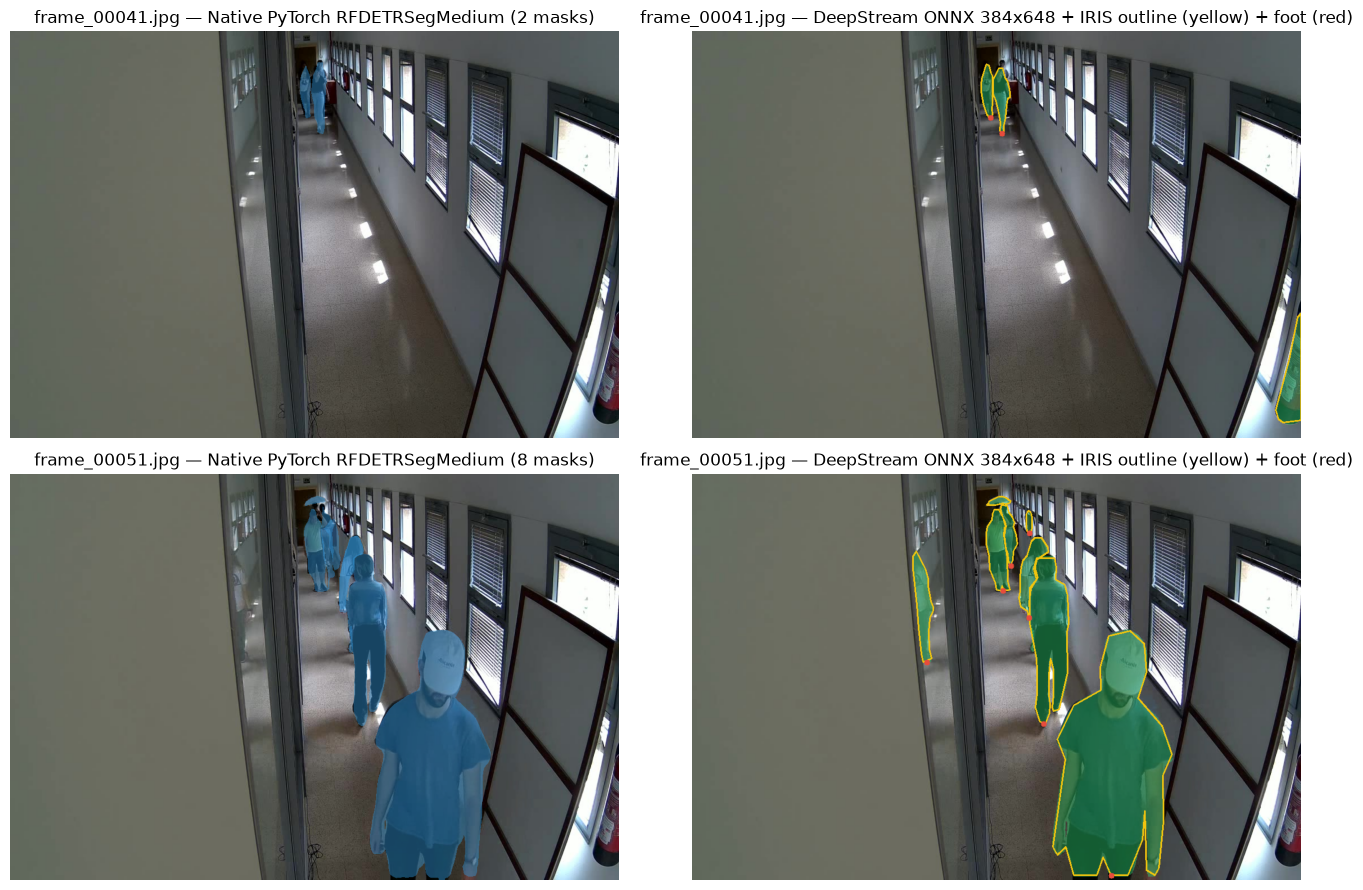

In [6]:
# Visual verification: compare PyTorch RF-DETR-Seg-M masks vs DeepStream ONNX + IRIS person_masks.outline polygons
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row_idx, name in enumerate(["frame_00041.jpg", "frame_00051.jpg"]):
    im, pt_det, _, _ = pt_results[name]
    orig_w, orig_h = im.size

    # Native PyTorch render
    c_pt = np.array(im, dtype=np.float32)
    if pt_det.mask is not None:
        for m_bool in pt_det.mask:
            c_pt[m_bool] = c_pt[m_bool] * 0.55 + np.array([52, 152, 219]) * 0.45
    axes[row_idx, 0].imshow(c_pt.clip(0, 255).astype(np.uint8))
    axes[row_idx, 0].set_title(f"{name} — Native PyTorch RFDETRSegMedium ({len(pt_det)} masks)")
    axes[row_idx, 0].axis("off")

    # DeepStream ONNX (384x648) -> decodeTensorYoloSeg -> IRIS outline() + person_shape()
    x_in = preprocess_nvinfer(im, 384, 648)
    y_out = sess_rect.run(["output"], {sess_rect.get_inputs()[0].name: x_in})[0][0]
    objs = decode_tensor_yolo_seg_python(y_out, 648, 384, len(seg_labels), threshold=CONF_THRESH)
    c_ds = np.array(im, dtype=np.float32)
    for o in objs:
        m_full = reconstruct_full_mask(o, orig_w, orig_h, 648, 384, thresh=0.5)
        c_ds[m_full] = c_ds[m_full] * 0.55 + np.array([46, 204, 113]) * 0.45
    canvas_ds = c_ds.clip(0, 255).astype(np.uint8)
    for o in objs:
        left, top = o["left"] * orig_w / 648, o["top"] * orig_h / 384
        w_px, h_px = o["width"] * orig_w / 648, o["height"] * orig_h / 384
        poly = outline(o["mask"].reshape(o["mask_height"], o["mask_width"]), 0.5, (left, top, w_px, h_px), (orig_w, orig_h))
        if poly:
            pts = np.array(poly, dtype=np.float32).reshape(-1, 2)
            pts_px = np.stack([pts[:, 0] * orig_w, pts[:, 1] * orig_h], axis=1).astype(np.int32)
            cv2.polylines(canvas_ds, [pts_px], True, (241, 196, 15), 2)
        imask = InstanceMask(values=o["mask"], width=o["mask_width"], height=o["mask_height"], threshold=0.5)
        blob = blob_of(imask, (left, top, w_px, h_px))
        if blob and o["classId"] == 0:
            ps = person_shape(blob, orig_h)
            cv2.circle(canvas_ds, (int(round(ps.foot[0])), int(round(ps.foot[1]))), 5, (231, 76, 60), -1)

    axes[row_idx, 1].imshow(canvas_ds)
    axes[row_idx, 1].set_title(f"{name} — DeepStream ONNX 384x648 + IRIS outline (yellow) + foot (red)")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.show()


## 5. Validate Candidate Barber `nvinfer` Config Against IRIS `engine_path`

Emit `notebooks/downloads/onnx_exports/config_infer_primary_rfdetr_seg_384x648.txt` and test `perception.engine.engine_path._parse` and `assert_distinct_engine_paths`.


In [7]:
CANDIDATE_SEG_CFG = ONNX_EXPORT_DIR / "config_infer_primary_rfdetr_seg_384x648.txt"
CANDIDATE_SEG_CFG.write_text(f"""[property]
gpu-id=0
net-scale-factor=0.0039215697906911373
model-color-format=0
onnx-file={ONNX_BARBER.name}
model-engine-file={ONNX_BARBER.name}_b3_gpu0_fp16.engine
labelfile-path=../../../perception/models/DeepStream-Yolo-Seg/labels.txt
batch-size=3
network-mode=2
num-detected-classes=80
interval=0
gie-unique-id=1
process-mode=1
network-type=3
cluster-mode=4
maintain-aspect-ratio=0
output-instance-mask=1
segmentation-threshold=0.5
parse-bbox-instance-mask-func-name=NvDsInferParseYoloSeg
custom-lib-path=/opt/nvidia/deepstream/deepstream/custom_parsers/libnvdsinfer_custom_impl_Yolo_seg.so

[class-attrs-all]
pre-cluster-threshold=0.35
topk=200
""", encoding="utf-8")

mode, onnx_rel, custom_engine, read_ok = parse_engine_cfg(str(CANDIDATE_SEG_CFG))
assert read_ok and not custom_engine
resolved_onnx = (CANDIDATE_SEG_CFG.parent / onnx_rel).resolve()
assert resolved_onnx.is_file()
face_cfg = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Face" / "config_sgie_face.txt"
_, face_onnx_rel, _, _ = parse_engine_cfg(str(face_cfg))
pgie_eng = f"{resolved_onnx}_b3_gpu0_{mode}.engine"
sgie_eng = f"{(face_cfg.parent / face_onnx_rel).resolve()}_b16_gpu0_fp32.engine"
assert_distinct_engine_paths([("pgie", str(CANDIDATE_SEG_CFG), pgie_eng), ("sgie_face", str(face_cfg), sgie_eng)])

print("Verified perception.engine.engine_path._parse()    : PASSED")
print(f"  mode={mode}, onnx={onnx_rel}, custom_engine_branch={custom_engine}")
print(f"  derived pgie engine : {Path(pgie_eng).name}")
print(f"  assert_distinct_engine_paths(pgie + sgie_face)  : PASSED")
print("\nFINAL TASK 2 (RF-DETR-Seg-M) VERDICT: CODEBASE COMPATIBLE (zero C++ parser edits needed via in-graph GridSample ROI crop!).")


Verified perception.engine.engine_path._parse()    : PASSED
  mode=fp16, onnx=rfdetr-seg-medium-ds-384x648.onnx, custom_engine_branch=False
  derived pgie engine : rfdetr-seg-medium-ds-384x648.onnx_b3_gpu0_fp16.engine
  assert_distinct_engine_paths(pgie + sgie_face)  : PASSED

FINAL TASK 2 (RF-DETR-Seg-M) VERDICT: CODEBASE COMPATIBLE (zero C++ parser edits needed via in-graph GridSample ROI crop!).
